In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
file = pd.ExcelFile('data.xlsx')
sns.set_theme(style='whitegrid')
sns.set_palette('Set2')

# Tratamento dos Dados

In [23]:
df = pd.read_excel(file)
df.columns = ['id', 'idade', 'genero', 'imc', 'glicemia', 'sistolica', 'diastolica', 'atividade', 'diabetes', 'hipertensao']
df.head(100)

,id,idade,genero,imc,glicemia,sistolica,diastolica,atividade,diabetes,hipertensao
0,1,29,Feminino,25.9,85,107,66,Alta,Não,Não
1,2,68,Feminino,33.5,119,125,83,Baixa,Não,Sim
2,3,61,Masculino,22.4,93,116,71,Moderada,Não,Não
3,4,49,Masculino,25.9,106,118,69,Moderada,Sim,Não
4,5,49,Masculino,34.9,118,107,81,Baixa,Não,Não
...,...,...,...,...,...,...,...,...,...,...
95,96,41,Feminino,29.2,109,107,72,Alta,Não,Não
96,97,38,Feminino,22.5,91,120,60,Moderada,Não,Não
97,98,63,Feminino,30.6,88,135,79,Baixa,Não,Sim
98,99,60,Masculino,26.7,109,130,68,Moderada,Não,Sim


# Análise

## Tabela Quantitativa

In [108]:
variaveis = ['glicemia', 'sistolica']

tabela = pd.DataFrame({
    'Média': df[variaveis].mean().round(2),
    'Moda': (
        df[variaveis]
        .mode()
        .apply(lambda col: ', '.join(col.dropna().map(lambda v: f'{v:g}')))
    ),
    'Desvio-Padrão': df[variaveis].std().round(2),
})


tabela.index = [
    'Glicemia em Jejum (mg/dL)',
    'Pressão Sistólica (mmHg)',
]

path = f'tables/quantitativas.csv'
tabela.to_csv(path, index=True, encoding='utf-8')

display(tabela)

,Média,Moda,Desvio-Padrão
Glicemia em Jejum (mg/dL),99.33,106,17.30
Pressão Sistólica (mmHg),120.67,130,15.01


## Hipertensão X Diabetes

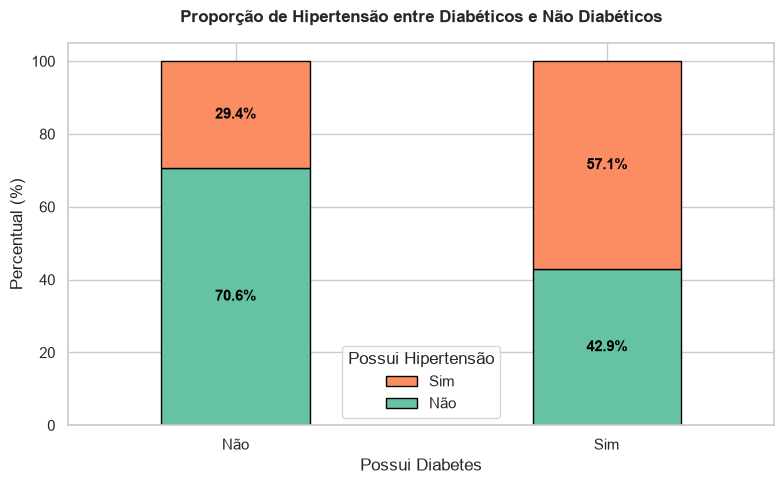

In [71]:
tabela_prop = (
    pd.crosstab(
        index=df['diabetes'],
        columns=df['hipertensao'],
        normalize='index'
    ) * 100
)
tabela_prop = tabela_prop.reindex(index=['Não', 'Sim'])

ax = tabela_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    edgecolor='black',
    width=0.4,
)

for c in ax.containers:
  labels = [f'{v.get_height():.1f}%' if v.get_height() > 0 else '' for v in c]
  ax.bar_label(
      c,
      labels=labels,
      label_type='center',
      fontsize=11,
      fontweight='bold',
      color='black',
  )

plt.title(
    'Proporção de Hipertensão entre Diabéticos e Não Diabéticos',
    pad=15,
    fontweight='bold',
)
plt.xlabel('Possui Diabetes')
plt.ylabel('Percentual (%)')
plt.xticks(rotation=0)
plt.legend(title='Possui Hipertensão', reverse=True)

plt.tight_layout()
plt.savefig('figures/fig1.png', dpi=300)
plt.show()

## Glicemia X Hipertensão

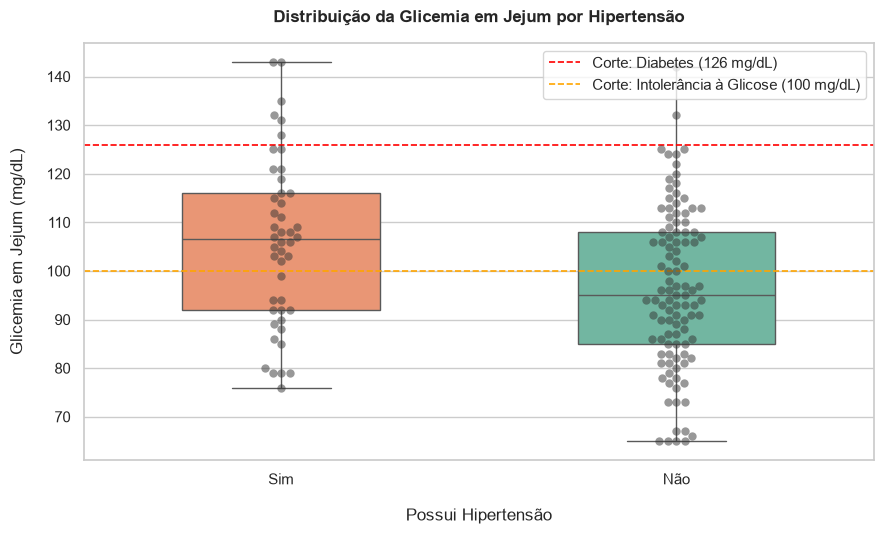

In [70]:
plt.figure(figsize=(9, 5.5))

ordem_atividade = ['Sim', 'Não']

ax = sns.boxplot(
    data=df,
    x='hipertensao',
    y='glicemia',
    hue='hipertensao',
    order=ordem_atividade,
    width=0.5,
    showfliers=False, #o swarmplot já vai revelar outliers
    legend=False,
)

sns.swarmplot(
    data=df,
    x='hipertensao',
    y='glicemia',
    order=ordem_atividade,
    color='#333333',
    alpha=0.5,
    size=6,
)

plt.axhline(
    100,
    color="orange",
    linestyle="--",
    linewidth=1.2,
    label="Corte: Intolerância à Glicose (100 mg/dL)",
)
plt.axhline(
    126,
    color="red",
    linestyle="--",
    linewidth=1.2,
    label="Corte: Diabetes (126 mg/dL)",
)
plt.legend(loc="upper right", reverse=True)


plt.title(
    'Distribuição da Glicemia em Jejum por Hipertensão',
    pad=15,
    fontweight='bold',
)
plt.xlabel("Possui Hipertensão", labelpad=15)
plt.ylabel("Glicemia em Jejum (mg/dL)", labelpad=15)

plt.tight_layout()
plt.show()

# Fonte: ABESO

# Glicemia X Pressão Sistólica X Hipertensão

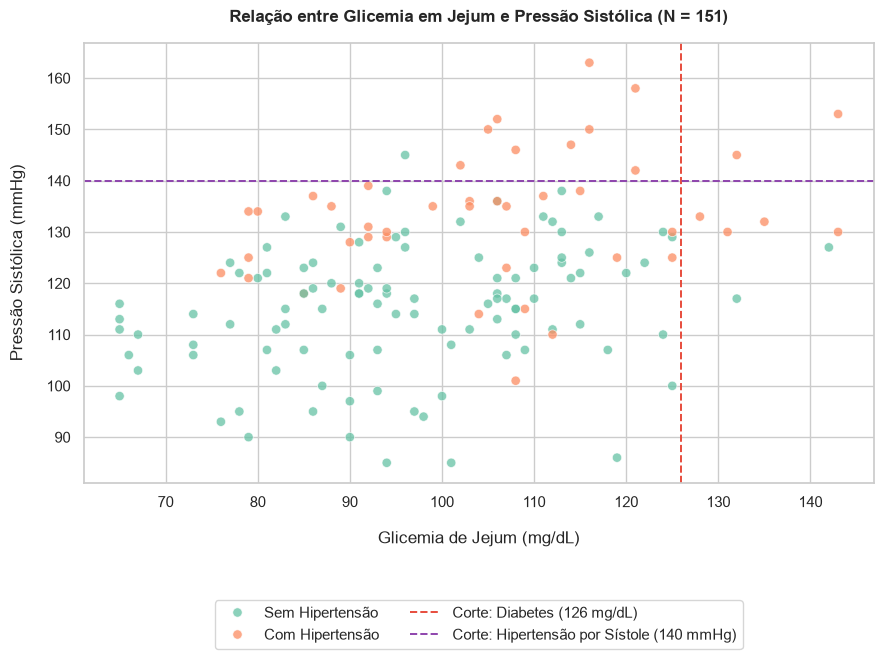

In [105]:
plt.figure(figsize=(9, 7))

ax = sns.scatterplot(
    data=df,
    x="glicemia",
    y="sistolica",
    hue="hipertensao",
    hue_order=["Não", "Sim"],
    s=45,
    alpha=0.75,
    edgecolor="white",
)

# Quadrantes de Referência.
plt.axvline(
    126,
    color="#e74c3c",
    linestyle="--",
    linewidth=1.4,
    label="Corte: Diabetes (126 mg/dL)",
)
plt.axhline(
    140,
    color="#8e44ad",
    linestyle="--",
    linewidth=1.4,
    label="Corte: Hipertensão por Sístole (140 mmHg)",
)

plt.title(
    "Relação entre Glicemia em Jejum e Pressão Sistólica (N = 151)",
    pad=15,
    fontweight="bold",
)
plt.xlabel("Glicemia de Jejum (mg/dL)", labelpad=15)
plt.ylabel("Pressão Sistólica (mmHg)", labelpad=15)

handles, labels = ax.get_legend_handles_labels()
mapa_nomes = {"Não": "Sem Hipertensão", "Sim": "Com Hipertensão"}
novos_labels = [mapa_nomes.get(texto, texto) for texto in labels]
plt.legend(
    handles=handles,
    labels=novos_labels,
    bbox_to_anchor=(0.5, -0.25),
    loc="upper center",
    ncol=2,
    frameon=True,
)

plt.tight_layout()
plt.show()

# FONTE: Sociedade Brasileira de Cardiologia